# Global Economic Indicators — Exploratory Data Analysis

## Overview
This project explores global economic and demographic indicators across 200+ countries, using data from the World Bank and IMF (2000–2025, with select indicators projected through 2031).

## Dataset
Source: [Global Country Economic Indicators (2000–2031)](https://www.kaggle.com/code/metricshour/global-country-economic-indicators-starter-eda) — Kaggle

Three files are used:
1. dictionary — metadata describing 81 indicators
2. country_reference — reference attributes for 250 countries
3. global_economic — 317,000+ rows of country × indicator × year values

## What This Notebook Covers
* Profiling and cleaning all three source tables
* Validating and merging tables into a single enriched dataset
* Exploring key indicators through multiple visualization types

In [304]:
from pathlib import Path
import numpy as np
import pandas as pd
DATA_PATH = Path("archive1")

In [305]:
dictionary=pd.read_csv(DATA_PATH / "data_dictionary.csv")
print(dictionary)

              indicator      category  \
0            birth_rate  Demographics   
1            death_rate  Demographics   
2      dependency_ratio  Demographics   
3        fertility_rate  Demographics   
4     imf_population_mn  Demographics   
..                  ...           ...   
76     poverty_rate_pct        Social   
77  tourism_revenue_usd       Tourism   
78     tourist_arrivals       Tourism   
79          exports_usd         Trade   
80          imports_usd         Trade   

                                   description              unit  n_countries  \
0                             Crude birth rate  per 1,000 people          215   
1                             Crude death rate  per 1,000 people          215   
2        Dependents per 100 working-age people             ratio          215   
3                     Average births per woman      births/woman          216   
4                          IMF WEO: population          millions          196   
..                   

In [306]:
original_dictionary = dictionary
print(dictionary.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   indicator    81 non-null     object
 1   category     81 non-null     object
 2   description  81 non-null     object
 3   unit         81 non-null     object
 4   n_countries  81 non-null     int64 
 5   n_rows       81 non-null     int64 
 6   year_min     81 non-null     int64 
 7   year_max     81 non-null     int64 
 8   sources      81 non-null     object
dtypes: int64(4), object(5)
memory usage: 5.8+ KB
None


In [307]:
print(dictionary.describe())

       n_countries       n_rows     year_min     year_max
count    81.000000    81.000000    81.000000    81.000000
mean    187.975309  3914.259259  2004.370370  2025.111111
std      38.391723  1385.599823     7.567107     2.544602
min       7.000000     7.000000  2000.000000  2020.000000
25%     190.000000  3236.000000  2000.000000  2024.000000
50%     196.000000  4561.000000  2000.000000  2025.000000
75%     204.000000  4999.000000  2015.000000  2025.000000
max     223.000000  5609.000000  2026.000000  2031.000000


In [308]:
print(dictionary.head())

           indicator      category                            description  \
0         birth_rate  Demographics                       Crude birth rate   
1         death_rate  Demographics                       Crude death rate   
2   dependency_ratio  Demographics  Dependents per 100 working-age people   
3     fertility_rate  Demographics               Average births per woman   
4  imf_population_mn  Demographics                    IMF WEO: population   

               unit  n_countries  n_rows  year_min  year_max     sources  
0  per 1,000 people          215    5160      2000      2023  world_bank  
1  per 1,000 people          215    5160      2000      2023  world_bank  
2             ratio          215    5375      2000      2024  world_bank  
3      births/woman          216    5382      2000      2024  world_bank  
4          millions          196    3286      2015      2031         imf  


In [309]:
print(dictionary.tail())

              indicator category                                 description  \
76     poverty_rate_pct   Social  Share below the international poverty line   
77  tourism_revenue_usd  Tourism              International tourism receipts   
78     tourist_arrivals  Tourism     International tourist arrivals per year   
79          exports_usd    Trade                   Total merchandise exports   
80          imports_usd    Trade                   Total merchandise imports   

      unit  n_countries  n_rows  year_min  year_max     sources  
76       %          168    1848      2000      2025  world_bank  
77     USD          196    3419      2000      2020  world_bank  
78  people          202    3826      2000      2020  world_bank  
79     USD          193    4561      2000      2025  world_bank  
80     USD          193    4561      2000      2025  world_bank  


In [310]:
dictionary['category'].value_counts()

category
Economy         21
Demographics    11
External         8
Fiscal           8
Social           8
Governance       6
Monetary         6
Labor            5
Environment      2
Innovation       2
Tourism          2
Trade            2
Name: count, dtype: int64

In [311]:
dictionary['sources'].value_counts()

sources
world_bank                                                 58
imf                                                        10
imf_weo|world_bank                                          5
imf_static|world_bank                                       2
imf_static                                                  1
oecd                                                        1
imf_weo                                                     1
world_bank|world_bank_wgi                                   1
ecb                                                         1
bis|central_bank|fred|manual|peg_eur|peg_usd|world_bank     1
Name: count, dtype: int64

In [312]:
dictionary['unit'].value_counts()

unit
%                         41
USD                       15
index (-2.5 to 2.5)        6
per 1,000 people           4
people                     3
years                      1
people/km2                 1
millions                   1
ratio                      1
USD billions               1
index (100=trend)          1
births/woman               1
count                      1
local currency per EUR     1
index (0-100)              1
per 1,000 births           1
per 100 people             1
Name: count, dtype: int64

In [313]:
print(dictionary.isnull().sum())

indicator      0
category       0
description    0
unit           0
n_countries    0
n_rows         0
year_min       0
year_max       0
sources        0
dtype: int64


In [314]:
dictionary.dropna()

,indicator,category,description,unit,n_countries,n_rows,year_min,year_max,sources
0,birth_rate,Demographics,Crude birth rate,"per 1,000 people",215,5160,2000,2023,world_bank
1,death_rate,Demographics,Crude death rate,"per 1,000 people",215,5160,2000,2023,world_bank
2,dependency_ratio,Demographics,Dependents per 100 working-age people,ratio,215,5375,2000,2024,world_bank
3,fertility_rate,Demographics,Average births per woman,births/woman,216,5382,2000,2024,world_bank
4,imf_population_mn,Demographics,IMF WEO: population,millions,196,3286,2015,2031,imf
...,...,...,...,...,...,...,...,...,...
76,poverty_rate_pct,Social,Share below the international poverty line,%,168,1848,2000,2025,world_bank
77,tourism_revenue_usd,Tourism,International tourism receipts,USD,196,3419,2000,2020,world_bank
78,tourist_arrivals,Tourism,International tourist arrivals per year,people,202,3826,2000,2020,world_bank
79,exports_usd,Trade,Total merchandise exports,USD,193,4561,2000,2025,world_bank


In [315]:
country_reference=pd.read_csv(DATA_PATH / "metricshour_country_reference.csv")
print(country_reference)

    country_code country_code3  numeric_code               country_name  \
0             AM           ARM          51.0                    Armenia   
1             PK           PAK         586.0                   Pakistan   
2             BJ           BEN         204.0                      Benin   
3             PM           SPM         666.0  Saint Pierre and Miquelon   
4             BY           BLR         112.0                    Belarus   
..           ...           ...           ...                        ...   
245           RE           REU         638.0                    Réunion   
246           KR           KOR         410.0                South Korea   
247           CW           CUW         531.0                    Curaçao   
248           BL           BLM         652.0           Saint Barthélemy   
249           ST           STP         678.0      São Tomé and Príncipe   

                                    name_official  capital_city    region  \
0                     

In [316]:
original_country_reference=country_reference
print(country_reference.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   country_code           249 non-null    object 
 1   country_code3          250 non-null    object 
 2   numeric_code           249 non-null    float64
 3   country_name           250 non-null    object 
 4   name_official          250 non-null    object 
 5   capital_city           246 non-null    object 
 6   region                 250 non-null    object 
 7   subregion              245 non-null    object 
 8   area_km2               250 non-null    float64
 9   landlocked             250 non-null    bool   
 10  island_nation          250 non-null    bool   
 11  government_type        0 non-null      float64
 12  currency_code          247 non-null    object 
 13  currency_name          247 non-null    object 
 14  exchange_rate_regime   0 non-null      float64
 15  is_g7 

In [317]:
print(country_reference.describe())

       numeric_code      area_km2  government_type  exchange_rate_regime  \
count    249.000000  2.500000e+02              0.0                   0.0   
mean     433.835341  6.010389e+05              NaN                   NaN   
std      252.980446  1.912575e+06              NaN                   NaN   
min        4.000000  4.900000e-01              NaN                   NaN   
25%      218.000000  1.194250e+03              NaN                   NaN   
50%      434.000000  6.492950e+04              NaN                   NaN   
75%      652.000000  3.841505e+05              NaN                   NaN   
max      894.000000  1.709825e+07              NaN                   NaN   

       development_status  credit_outlook_sp  credit_rating_moodys  \
count                 0.0                0.0                   0.0   
mean                  NaN                NaN                   NaN   
std                   NaN                NaN                   NaN   
min                   NaN          

In [318]:
print(country_reference.head())

  country_code country_code3  numeric_code               country_name  \
0           AM           ARM          51.0                    Armenia   
1           PK           PAK         586.0                   Pakistan   
2           BJ           BEN         204.0                      Benin   
3           PM           SPM         666.0  Saint Pierre and Miquelon   
4           BY           BLR         112.0                    Belarus   

                  name_official  capital_city    region       subregion  \
0           Republic of Armenia       Yerevan      Asia    Western Asia   
1  Islamic Republic of Pakistan     Islamabad      Asia   Southern Asia   
2             Republic of Benin    Porto-Novo    Africa  Western Africa   
3     Saint Pierre and Miquelon  Saint-Pierre  Americas   North America   
4           Republic of Belarus         Minsk    Europe  Eastern Europe   

   area_km2  landlocked  ...  development_status  credit_rating_sp  \
0   29743.0        True  ...            

In [319]:
print(country_reference.tail())

    country_code country_code3  numeric_code           country_name  \
245           RE           REU         638.0                Réunion   
246           KR           KOR         410.0            South Korea   
247           CW           CUW         531.0                Curaçao   
248           BL           BLM         652.0       Saint Barthélemy   
249           ST           STP         678.0  São Tomé and Príncipe   

                                    name_official capital_city    region  \
245                                Réunion Island  Saint-Denis    Africa   
246                             Republic of Korea        Seoul      Asia   
247                            Country of Curaçao   Willemstad  Americas   
248              Collectivity of Saint Barthélemy     Gustavia  Americas   
249  Democratic Republic of São Tomé and Príncipe     São Tomé    Africa   

          subregion  area_km2  landlocked  ...  development_status  \
245  Eastern Africa    2511.0       False  ...

In [320]:
country_reference.isnull().sum()

country_code               1
country_code3              0
numeric_code               1
country_name               0
name_official              0
capital_city               4
region                     0
subregion                  5
area_km2                   0
landlocked                 0
island_nation              0
government_type          250
currency_code              3
currency_name              3
exchange_rate_regime     250
is_g7                      0
is_g20                     0
is_eu                      0
is_eurozone                0
is_nato                    0
is_opec                    0
is_brics                   0
is_asean                   0
is_oecd                    0
is_commonwealth            0
income_level              36
development_status       250
credit_rating_sp          67
credit_outlook_sp        250
credit_rating_moodys     250
credit_outlook_moodys    250
credit_rating_fitch      250
credit_outlook_fitch     250
commodity_dependent      250
calling_code  

In [321]:
null_counts = metricshour.isnull().sum()
total_rows = len(metricshour)
empty_columns = null_counts[null_counts == total_rows]
print("Fully empty columns:")
print(empty_columns)

Fully empty columns:
government_type          250
exchange_rate_regime     250
development_status       250
credit_outlook_sp        250
credit_rating_moodys     250
credit_outlook_moodys    250
credit_rating_fitch      250
credit_outlook_fitch     250
commodity_dependent      250
dtype: int64


In [322]:
empty_cols = ['government_type', 'exchange_rate_regime', 'development_status',
              'credit_outlook_sp', 'credit_rating_moodys', 'credit_outlook_moodys',
              'credit_rating_fitch', 'credit_outlook_fitch', 'commodity_dependent']

country_reference_clean = metricshour.drop(columns=empty_cols)
fill_values = {
    'capital_city': 'Unknown',
    'subregion': 'Unknown',
    'currency_code': 'Unknown',
    'currency_name': 'Unknown',
    'income_level': 'Unclassified',
    'credit_rating_sp': 'NR',
    'country_code': 'Unknown',
    'numeric_code': 0,
    'calling_code': 0,
    'tld': 'Unknown'
}
country_reference_clean = country_reference_clean.fillna(fill_values)
print(country_reference_clean.isnull().sum())

country_code        0
country_code3       0
numeric_code        0
country_name        0
name_official       0
capital_city        0
region              0
subregion           0
area_km2            0
landlocked          0
island_nation       0
currency_code       0
currency_name       0
is_g7               0
is_g20              0
is_eu               0
is_eurozone         0
is_nato             0
is_opec             0
is_brics            0
is_asean            0
is_oecd             0
is_commonwealth     0
income_level        0
credit_rating_sp    0
calling_code        0
tld                 0
dtype: int64


In [323]:
global_economic=pd.read_csv(DATA_PATH / "metricshour_global_economic_indicators.csv")
print(global_economic)

       country_code country_code3 country_name  region  income_level  \
0                AD           AND      Andorra  Europe          high   
1                AD           AND      Andorra  Europe          high   
2                AD           AND      Andorra  Europe          high   
3                AD           AND      Andorra  Europe          high   
4                AD           AND      Andorra  Europe          high   
...             ...           ...          ...     ...           ...   
317050           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317051           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317052           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317053           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317054           ZW           ZWE     Zimbabwe  Africa  lower_middle   

                     indicator category      value unit  year period_date  \
0          agriculture_pct_gdp  Economy   0.546368    %  2

In [324]:
print(global_economic.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 317055 entries, 0 to 317054
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   country_code   315527 non-null  object 
 1   country_code3  317055 non-null  object 
 2   country_name   317055 non-null  object 
 3   region         317055 non-null  object 
 4   income_level   313842 non-null  object 
 5   indicator      317055 non-null  object 
 6   category       317055 non-null  object 
 7   value          317055 non-null  float64
 8   unit           317055 non-null  object 
 9   year           317055 non-null  int64  
 10  period_date    317055 non-null  object 
 11  period_type    317055 non-null  object 
 12  source         317055 non-null  object 
dtypes: float64(1), int64(1), object(11)
memory usage: 31.4+ MB
None


In [325]:
print(global_economic.describe())

              value           year
count  3.170550e+05  317055.000000
mean   1.951797e+10    2013.820003
std    3.615921e+11       7.812737
min   -3.434028e+11    2000.000000
25%    2.237980e+00    2007.000000
50%    1.970000e+01    2014.000000
75%    1.022819e+02    2020.000000
max    4.125982e+13    2031.000000


In [326]:
print(global_economic.head())

  country_code country_code3 country_name  region income_level  \
0           AD           AND      Andorra  Europe         high   
1           AD           AND      Andorra  Europe         high   
2           AD           AND      Andorra  Europe         high   
3           AD           AND      Andorra  Europe         high   
4           AD           AND      Andorra  Europe         high   

             indicator category     value unit  year period_date period_type  \
0  agriculture_pct_gdp  Economy  0.546368    %  2018  2018-01-01      annual   
1  agriculture_pct_gdp  Economy  0.522633    %  2019  2019-01-01      annual   
2  agriculture_pct_gdp  Economy  0.559443    %  2020  2020-01-01      annual   
3  agriculture_pct_gdp  Economy  0.531845    %  2021  2021-01-01      annual   
4  agriculture_pct_gdp  Economy  0.487492    %  2022  2022-01-01      annual   

       source  
0  world_bank  
1  world_bank  
2  world_bank  
3  world_bank  
4  world_bank  


In [327]:
print(global_economic.tail())

       country_code country_code3 country_name  region  income_level  \
317050           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317051           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317052           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317053           ZW           ZWE     Zimbabwe  Africa  lower_middle   
317054           ZW           ZWE     Zimbabwe  Africa  lower_middle   

                     indicator category   value unit  year period_date  \
317050  youth_unemployment_pct    Labor  15.208    %  2021  2021-01-01   
317051  youth_unemployment_pct    Labor  16.984    %  2022  2022-01-01   
317052  youth_unemployment_pct    Labor  15.332    %  2023  2023-01-01   
317053  youth_unemployment_pct    Labor  15.429    %  2024  2024-01-01   
317054  youth_unemployment_pct    Labor  15.548    %  2025  2025-01-01   

       period_type      source  
317050      annual  world_bank  
317051      annual  world_bank  
317052      annual  wor

In [328]:
print(global_economic.isnull().sum())

country_code     1528
country_code3       0
country_name        0
region              0
income_level     3213
indicator           0
category            0
value               0
unit                0
year                0
period_date         0
period_type         0
source              0
dtype: int64


In [329]:
global_economic['indicator'].nunique()      
global_economic[global_economic['country_code'].isnull()]  
global_economic['country_code3'].nunique()  

236

In [330]:
global_economic['country_code'] = global_economic['country_code'].fillna('Unknown')

In [331]:
global_economic['income_level'] = global_economic['income_level'].fillna('Unclassified')

In [332]:
print(global_economic.isnull().sum())

country_code     0
country_code3    0
country_name     0
region           0
income_level     0
indicator        0
category         0
value            0
unit             0
year             0
period_date      0
period_type      0
source           0
dtype: int64


In [333]:
codes_data = set(global_economic['country_code3'].unique())
codes_ref = set(country_reference['country_code3'].unique())
print("Unique in global_economic:", len(codes_data))
print("Unique in country_reference:", len(codes_ref))

Unique in global_economic: 236
Unique in country_reference: 250


In [334]:
missing_in_ref = codes_data - codes_ref
print("Missing from country_reference:", missing_in_ref)
print("Count:", len(missing_in_ref))

Missing from country_reference: set()
Count: 0


In [335]:
missing_in_data = codes_ref - codes_data
print("Missing from global_economic:", missing_in_data)
print("Count:", len(missing_in_data))

Missing from global_economic: {'CCK', 'CXR', 'NFK', 'BVT', 'ESH', 'MSR', 'TKL', 'SGS', 'AIA', 'ATA', 'PCN', 'HMD', 'SJM', 'SHN'}
Count: 14


In [336]:
date_format = "%Y-%m-%d"
timestamp_checks = pd.Series({
    "global_economic": pd.to_datetime(global_economic["period_date"], format=date_format, errors="coerce").isna().sum()
})
print(timestamp_checks)

global_economic    0
dtype: int64


In [337]:
global_economic['period_date'] = pd.to_datetime(global_economic['period_date'], format=date_format)

In [338]:
global_economic['period_date'] = pd.to_datetime(global_economic['period_date'], format="%Y-%m-%d")
print(global_economic.dtypes['period_date'])

datetime64[ns]


In [339]:
merged = global_economic.merge(
    country_reference,
    on="country_code3",
    how="left",
    validate="many_to_one",
    suffixes=('', '_ref')
)
merged = merged.merge(
    dictionary[['indicator', 'description', 'unit']],
    on="indicator",
    how="left",
    validate="many_to_one"
)
merged = merged.sort_values(["country_code3", "indicator", "year"]).reset_index(drop=True)
print(merged.shape)

print(merged.columns.tolist())

(317055, 50)
['country_code', 'country_code3', 'country_name', 'region', 'income_level', 'indicator', 'category', 'value', 'unit_x', 'year', 'period_date', 'period_type', 'source', 'country_code_ref', 'numeric_code', 'country_name_ref', 'name_official', 'capital_city', 'region_ref', 'subregion', 'area_km2', 'landlocked', 'island_nation', 'government_type', 'currency_code', 'currency_name', 'exchange_rate_regime', 'is_g7', 'is_g20', 'is_eu', 'is_eurozone', 'is_nato', 'is_opec', 'is_brics', 'is_asean', 'is_oecd', 'is_commonwealth', 'income_level_ref', 'development_status', 'credit_rating_sp', 'credit_outlook_sp', 'credit_rating_moodys', 'credit_outlook_moodys', 'credit_rating_fitch', 'credit_outlook_fitch', 'commodity_dependent', 'calling_code', 'tld', 'description', 'unit_y']


In [340]:
merged = merged.drop(columns=[
    'country_name_ref', 'region_ref', 'income_level_ref', 'unit_y',
    'government_type', 'exchange_rate_regime', 'development_status',
    'credit_outlook_sp', 'credit_rating_moodys', 'credit_outlook_moodys',
    'credit_rating_fitch', 'credit_outlook_fitch', 'commodity_dependent'
])
merged = merged.rename(columns={'unit_x': 'unit'})
print(merged.shape)
print(merged.columns.tolist())

(317055, 37)
['country_code', 'country_code3', 'country_name', 'region', 'income_level', 'indicator', 'category', 'value', 'unit', 'year', 'period_date', 'period_type', 'source', 'country_code_ref', 'numeric_code', 'name_official', 'capital_city', 'subregion', 'area_km2', 'landlocked', 'island_nation', 'currency_code', 'currency_name', 'is_g7', 'is_g20', 'is_eu', 'is_eurozone', 'is_nato', 'is_opec', 'is_brics', 'is_asean', 'is_oecd', 'is_commonwealth', 'credit_rating_sp', 'calling_code', 'tld', 'description']


In [341]:
poverty = merged[merged['indicator'] == 'poverty_rate_pct']
latest = poverty.sort_values('year').groupby('country_code3').tail(1)
avg_by_income = latest.groupby("income_level", as_index=False).agg(
    avg_poverty_rate=("value", "mean")
)
avg_by_income = avg_by_income.sort_values(by="avg_poverty_rate", ascending=False)
avg_by_income

,income_level,avg_poverty_rate
2,low,49.680952
0,Unclassified,24.150000
3,lower_middle,20.000000
4,upper_middle,3.332653
1,high,0.706383


# Poverty Rate by Income Level

The data shows a clear economic gradient:
poverty rate drops sharply asincome level rises, from ~50% in low-income countries to under 1% in high-income countries. This confirms income classification is a strong predictor of poverty outcomes.

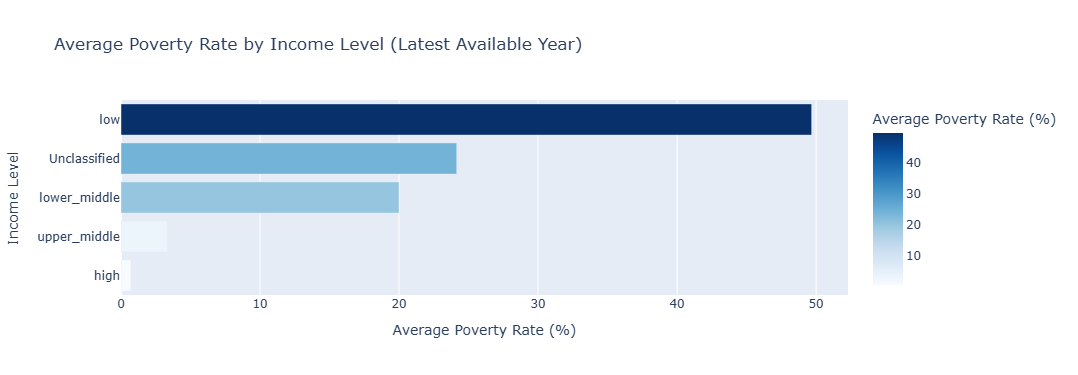

In [342]:
import plotly.express as px

poverty = merged[merged['indicator'] == 'poverty_rate_pct']
latest = poverty.sort_values('year').groupby('country_code3').tail(1)
avg_by_income = latest.groupby('income_level', as_index=False)['value'].mean()
avg_by_income = avg_by_income.sort_values('value')

fig = px.bar(
    avg_by_income,
    x='value',
    y='income_level',
    orientation='h',
    labels={'value': 'Average Poverty Rate (%)', 'income_level': 'Income Level'},
    title='Average Poverty Rate by Income Level (Latest Available Year)',
    color='value',
    color_continuous_scale='Blues'
)
fig.show()

## Distribution of Poverty Rate Across Countries

This histogram shows how poverty rate values are distributed across all countries, using each countrys most recent available data.
Each bar represents a range of poverty rates, and its height shows how many countries fall into that range.


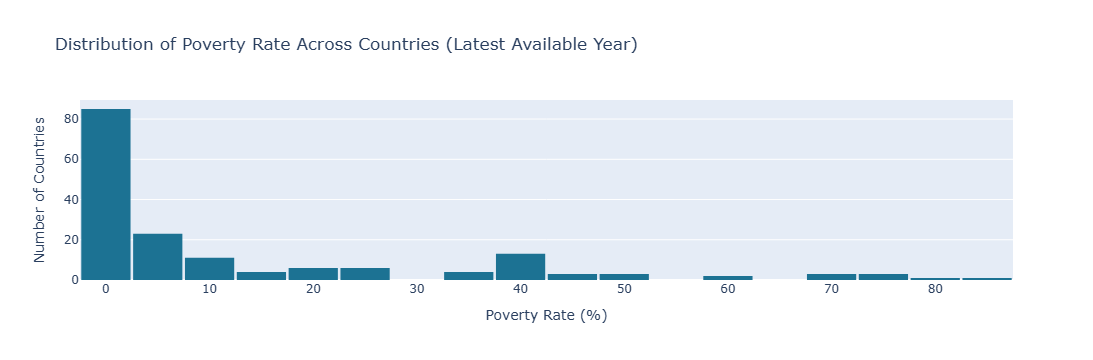

In [343]:
import plotly.express as px

poverty = merged[merged['indicator'] == 'poverty_rate_pct']
latest = poverty.sort_values('year').groupby('country_code3').tail(1)
fig = px.histogram(
    latest,
    x='value',
    nbins=20,
    labels={'value': 'Poverty Rate (%)'},
    title='Distribution of Poverty Rate Across Countries (Latest Available Year)',
    color_discrete_sequence=['#1C7293']
)

fig.update_layout(
    xaxis_title='Poverty Rate (%)',
    yaxis_title='Number of Countries',
    bargap=0.05
)

fig.show()

## Share of Countries by Region

Shows what proportion of all countries in the dataset fall into each region —
useful context for interpreting the region-based comparisons elsewhere in
this analysis.

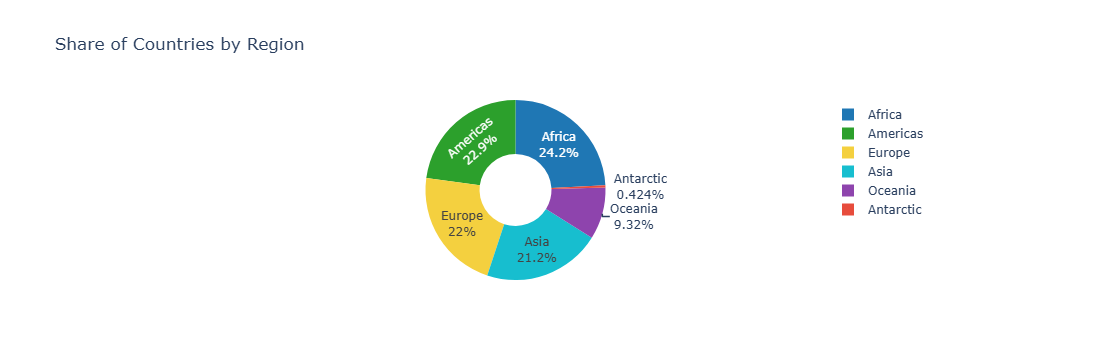

In [344]:
import plotly.express as px

country_counts = merged[['country_code3', 'region']].drop_duplicates()
region_counts = country_counts['region'].value_counts().reset_index()
region_counts.columns = ['region', 'count']

fig = px.pie(
    region_counts,
    names='region',
    values='count',
    title='Share of Countries by Region',
    color='region',
    color_discrete_map=region_colors,   # reuse your existing fixed region palette
    hole=0.4
)

fig.update_traces(textinfo='percent+label')
fig.show()

## Fertility Rate Distribution by Region

This violin plot shows the distribution of fertility rate (average births per
woman) across countries, grouped by region. Unlike a box plot, the violin
shape reveals the full density of the data — wider sections show where more
countries cluster, while narrower sections show less common values.


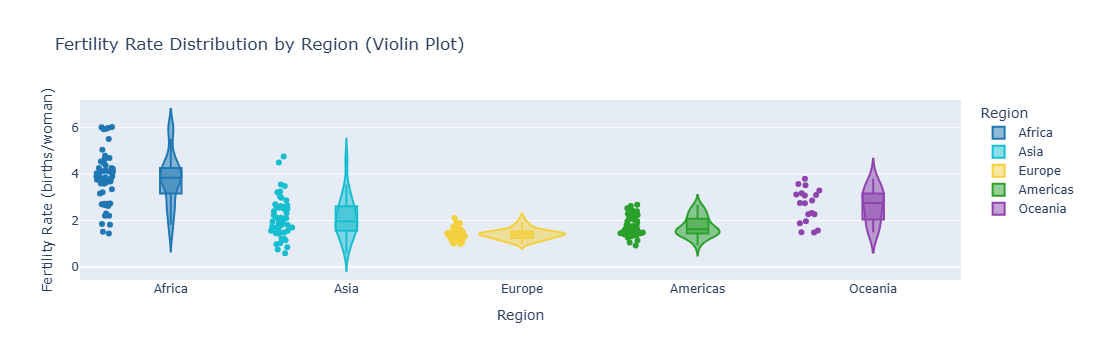

In [345]:
fertility = merged[merged['indicator'] == 'fertility_rate']
latest_fert = fertility.sort_values('year').groupby('country_code3').tail(1)

fig = px.violin(
    latest_fert,
    x='region',
    y='value',
    color='region',
    category_orders={'region': list(region_colors.keys())},
    color_discrete_map=region_colors,
    box=True,
    points='all',
    hover_name='country_name',
    labels={'value': 'Fertility Rate (births/woman)', 'region': 'Region'},
    title='Fertility Rate Distribution by Region (Violin Plot)'
)

fig.show()

 #  Poverty Rate Trend by Income Level

The data shows that poverty rates generally remain higher in lower-income countries throughout the observed period, while higher-income countries have consistently lower rates. The trend highlights a clear relationship between income level and poverty over time.

In [346]:
poverty = merged[merged['indicator'] == 'poverty_rate_pct']

trend_by_income = poverty.groupby(["year", "income_level"], as_index=False).agg(
    avg_poverty_rate=("value", "mean")
)
trend_by_income = trend_by_income.sort_values(by=["year", "income_level"])
trend_by_income

,year,income_level,avg_poverty_rate
0,2000,high,2.207143
1,2000,low,82.300000
2,2000,lower_middle,42.483333
3,2000,upper_middle,23.962500
4,2001,Unclassified,14.700000
...,...,...,...
105,2024,lower_middle,8.000000
106,2024,upper_middle,3.316667
107,2025,high,0.800000
108,2025,lower_middle,2.300000


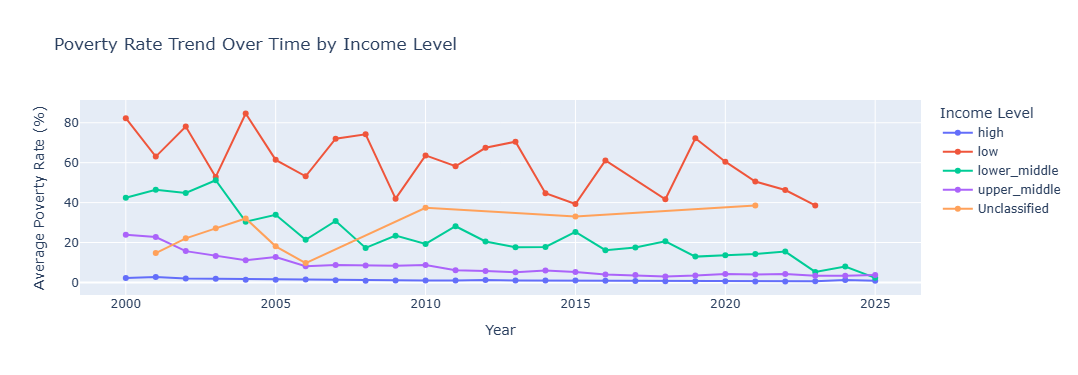

In [347]:
import plotly.express as px

poverty = merged[merged['indicator'] == 'poverty_rate_pct']

trend = poverty.groupby(['year', 'income_level'], as_index=False)['value'].mean()

fig = px.line(
    trend,
    x='year',
    y='value',
    color='income_level',
    labels={'value': 'Average Poverty Rate (%)', 'year': 'Year', 'income_level': 'Income Level'},
    title='Poverty Rate Trend Over Time by Income Level',
    markers=True
)

fig.show()

In [348]:
poverty = merged[merged['indicator'] == 'poverty_rate_pct']

trend_by_income = poverty.groupby(["year", "income_level"], as_index=False).agg(
    avg_poverty_rate=("value", "mean")
)
trend_by_income = trend_by_income.sort_values(by=["year", "income_level"])
trend_by_income

,year,income_level,avg_poverty_rate
0,2000,high,2.207143
1,2000,low,82.300000
2,2000,lower_middle,42.483333
3,2000,upper_middle,23.962500
4,2001,Unclassified,14.700000
...,...,...,...
105,2024,lower_middle,8.000000
106,2024,upper_middle,3.316667
107,2025,high,0.800000
108,2025,lower_middle,2.300000


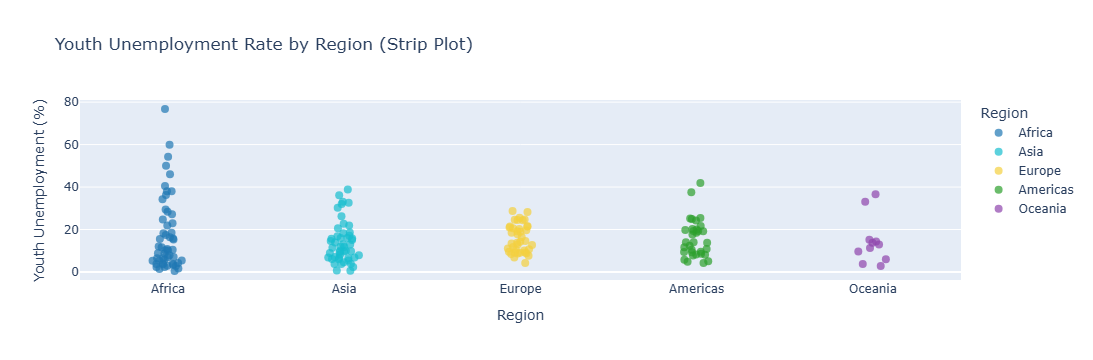

In [349]:
import plotly.express as px

unemployment = merged[merged['indicator'] == 'youth_unemployment_pct']
latest_unemp = unemployment.sort_values('year').groupby('country_code3').tail(1)

fig = px.strip(
    latest_unemp,
    x='region',
    y='value',
    color='region',
    category_orders={'region': list(region_colors.keys())},
    color_discrete_map=region_colors,
    hover_name='country_name',
    labels={'value': 'Youth Unemployment (%)', 'region': 'Region'},
    title='Youth Unemployment Rate by Region (Strip Plot)'
)

fig.update_traces(jitter=0.4, marker=dict(size=8, opacity=0.7))

fig.show()

 # Global Poverty Rate by Country

The data shows noticeable differences in poverty rates across countries, with higher rates concentrated in lower-income regions and lower rates generally observed in higher-income countries. The world map provides a clear geographical view of global poverty patterns using the latest available data for each country.

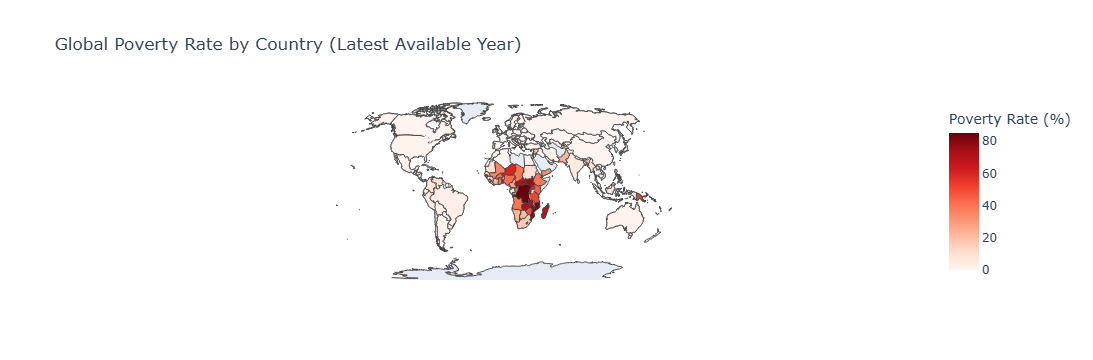

In [350]:
import plotly.express as px

poverty = merged[merged['indicator'] == 'poverty_rate_pct']
latest = poverty.sort_values('year').groupby('country_code3').tail(1)

fig = px.choropleth(
    latest,
    locations='country_code3',
    color='value',
    hover_name='country_name',
    hover_data={'year': True, 'income_level': True, 'value': ':.1f'},
    color_continuous_scale='Reds',
    labels={'value': 'Poverty Rate (%)'},
    title='Global Poverty Rate by Country (Latest Available Year)'
)

fig.update_layout(
    geo=dict(showframe=False, showcoastlines=True, projection_type='natural earth')
)
fig.show()

 # Poverty Rate Over Time by Country

The animated world map shows how poverty rates vary across countries and change over time. It highlights geographical differences in poverty and makes it easier to observe how poverty patterns evolve across the observed years.

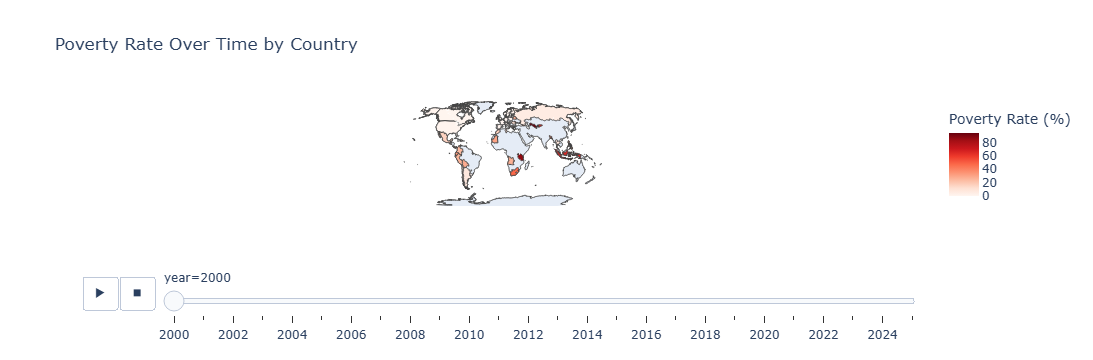

In [351]:
import plotly.express as px
poverty = merged[merged['indicator'] == 'poverty_rate_pct'].copy()
poverty = poverty.sort_values('year')

fig = px.choropleth(
    poverty,
    locations='country_code3',
    color='value',
    hover_name='country_name',
    animation_frame='year',
    color_continuous_scale='Reds',
    range_color=(poverty['value'].min(), poverty['value'].max()),
    labels={'value': 'Poverty Rate (%)'},
    title='Poverty Rate Over Time by Country'
)

fig.update_layout(
    geo=dict(showframe=False, showcoastlines=True, projection_type='natural earth')
)
fig.show()

In [352]:
print(merged['region'].unique())

['Americas' 'Asia' 'Africa' 'Europe' 'Oceania' 'Antarctic']


 # GDP per Capita by Region

The data shows how GDP per capita changes across different regions from 2000 to 2024. The line chart highlights regional differences and makes it easy to compare economic growth and trends over time.

In [353]:
dictionary[dictionary['indicator'].str.contains('gdp_per_capita', case=False)]

,indicator,category,description,unit,n_countries,n_rows,year_min,year_max,sources
16,gdp_per_capita,Economy,"Nominal GDP per capita (legacy series, limited...",USD,7,7,2022,2024,imf_static
17,gdp_per_capita_ppp,Economy,"GDP per capita, PPP adjusted (alt. vintage)",USD,199,1572,2018,2025,world_bank
18,gdp_per_capita_ppp_usd,Economy,"GDP per capita, PPP adjusted",USD,202,4921,2000,2024,world_bank
19,gdp_per_capita_usd,Economy,Nominal GDP per capita,USD,213,5395,2000,2025,world_bank
26,imf_gdp_per_capita_usd,Economy,IMF WEO: GDP per capita,USD,196,3279,2015,2031,imf


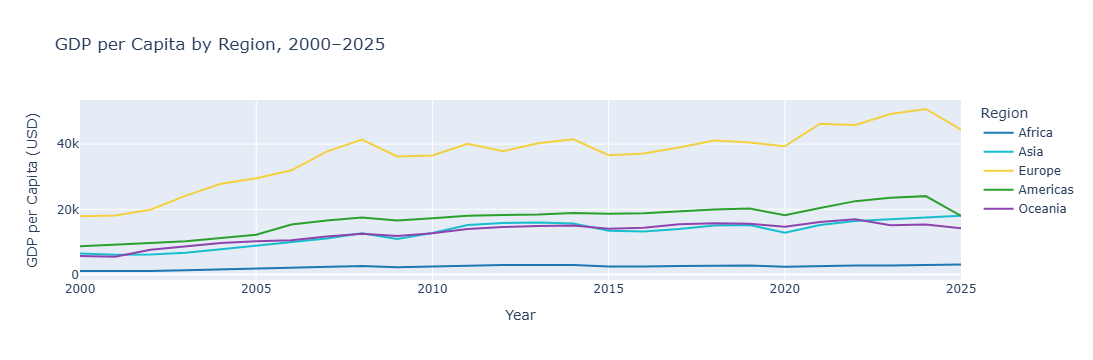

In [354]:
gdp = merged[merged['indicator'] == 'gdp_per_capita_usd'].copy()
gdp = gdp[(gdp['year'] >= 2000) & (gdp['year'] <= 2025)]   
trend = gdp.groupby(['year', 'region'], as_index=False)['value'].mean()

fig = px.line(
    trend,
    x='year',
    y='value',
    color='region',
    category_orders={'region': list(region_colors.keys())},
    color_discrete_map=region_colors,
    labels={'value': 'GDP per Capita (USD)', 'year': 'Year', 'region': 'Region'},
    title='GDP per Capita by Region, 2000–2025',
    markers=False
)
fig.show()

 # GDP per Capita vs. Poverty Rate

The data shows a negative relationship between GDP per capita and poverty rate: countries with higher GDP per capita generally tend to have lower poverty rates. The scatter plot highlights this relationship across countries and regions using the latest available data.

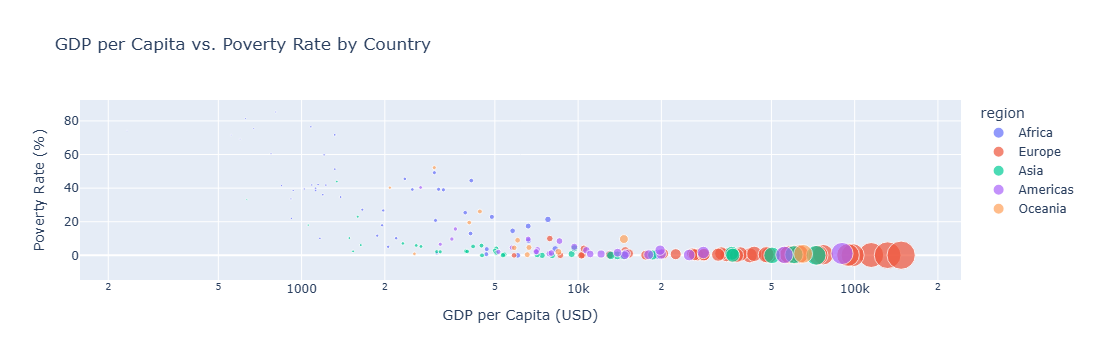

In [355]:
import plotly.express as px

gdp = merged[merged['indicator'] == 'gdp_per_capita_usd']
gdp_latest = gdp.sort_values('year').groupby('country_code3', as_index=False).agg(
    gdp_per_capita=("value", "last")
)

poverty = merged[merged['indicator'] == 'poverty_rate_pct']
poverty_latest = poverty.sort_values('year').groupby('country_code3', as_index=False).agg(
    poverty_rate=("value", "last")
)

country_info = merged[['country_code3', 'country_name', 'region', 'income_level']].drop_duplicates('country_code3')

scatter_data = gdp_latest.merge(poverty_latest, on='country_code3').merge(country_info, on='country_code3')

fig = px.scatter(
    scatter_data,
    x='gdp_per_capita',
    y='poverty_rate',
    color='region',
    hover_name='country_name',
    size='gdp_per_capita',
    labels={'gdp_per_capita': 'GDP per Capita (USD)', 'poverty_rate': 'Poverty Rate (%)'},
    title='GDP per Capita vs. Poverty Rate by Country',
    log_x=True   
)
fig.show()

 # GDP per Capita vs. Poverty Rate Over Time

The visualization shows how the relationship between GDP per capita and poverty rate changes across countries over time. The animated scatter plot highlights that countries with higher GDP per capita generally tend to have lower poverty rates, while also showing differences across regions.

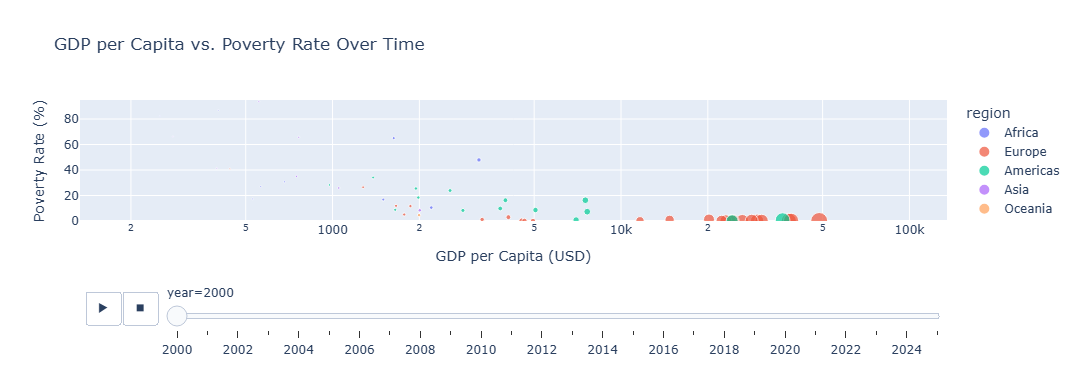

In [356]:
import plotly.express as px

gdp = merged[merged['indicator'] == 'gdp_per_capita_usd'].groupby(
    ['year', 'country_code3'], as_index=False
).agg(gdp_per_capita=("value", "mean"))

poverty = merged[merged['indicator'] == 'poverty_rate_pct'].groupby(
    ['year', 'country_code3'], as_index=False
).agg(poverty_rate=("value", "mean"))

country_info = merged[['country_code3', 'country_name', 'region']].drop_duplicates('country_code3')

scatter_data = gdp.merge(poverty, on=['year', 'country_code3']).merge(country_info, on='country_code3')
scatter_data = scatter_data.sort_values('year')

fig = px.scatter(
    scatter_data,
    x='gdp_per_capita',
    y='poverty_rate',
    color='region',
    hover_name='country_name',
    size='gdp_per_capita',
    animation_frame='year',
    labels={'gdp_per_capita': 'GDP per Capita (USD)', 'poverty_rate': 'Poverty Rate (%)'},
    title='GDP per Capita vs. Poverty Rate Over Time',
    log_x=True,
    range_x=[scatter_data['gdp_per_capita'].min(), scatter_data['gdp_per_capita'].max()],
    range_y=[0, scatter_data['poverty_rate'].max()]
)
fig.show()

  # Poverty Rate Distribution by Income Level

The box plot shows how poverty rates are distributed across different income levels. Lower-income groups generally have higher poverty rates and greater variation, while higher-income groups tend to have lower and more consistent poverty rates. The individual points represent the poverty rate of each country.

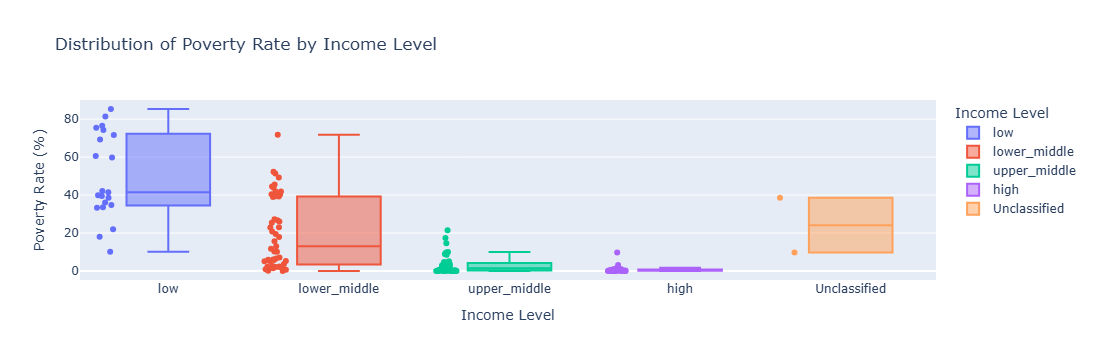

In [357]:
import plotly.express as px

poverty = merged[merged['indicator'] == 'poverty_rate_pct']
latest = poverty.sort_values('year').groupby('country_code3').tail(1)

fig = px.box(
    latest,
    x='income_level',
    y='value',
    color='income_level',
    category_orders={'income_level': ['low', 'lower_middle', 'upper_middle', 'high']},
    points='all',   # shows every country as a dot on top of the box
    hover_name='country_name',
    labels={'value': 'Poverty Rate (%)', 'income_level': 'Income Level'},
    title='Distribution of Poverty Rate by Income Level'
)

fig.show()

 # Correlation Between Key Economic Indicators

The correlation matrix shows the strength and direction of relationships between key economic indicators such as GDP per capita, poverty rate, fertility rate, youth unemployment, and life expectancy. The heatmap makes it easy to identify positive and negative correlations and understand how these indicators are related across countries.

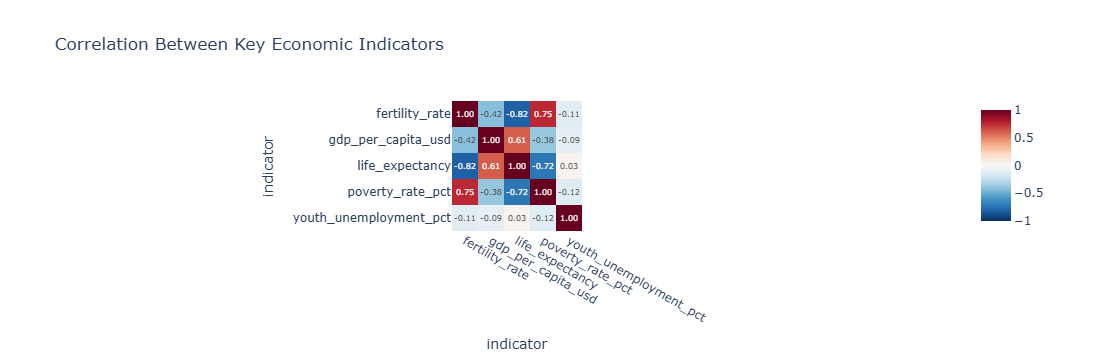

In [358]:
import plotly.express as px

indicators_of_interest = [
    'gdp_per_capita_usd', 'poverty_rate_pct', 'fertility_rate',
    'youth_unemployment_pct', 'life_expectancy' 
]

subset = merged[merged['indicator'].isin(indicators_of_interest)]

latest = subset.sort_values('year').groupby(['country_code3', 'indicator'], as_index=False).agg(
    value=('value', 'last')
)

pivoted = latest.pivot(index='country_code3', columns='indicator', values='value')

corr = pivoted.corr()

fig = px.imshow(
    corr,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1, zmax=1,
    title='Correlation Between Key Economic Indicators'
)
fig.show()

## Tourist Arrivals Trend Analysis

This analysis examines the trend in tourist arrivals across different regions from 2000 to 2020. The data is filtered to include only the 
`tourist_arrivals` indicator and the selected year range. The average tourist arrivals are calculated for each region and year using the `groupby()` function. A Plotly line chart is then used to visualize and compare tourism trends across regions over time.


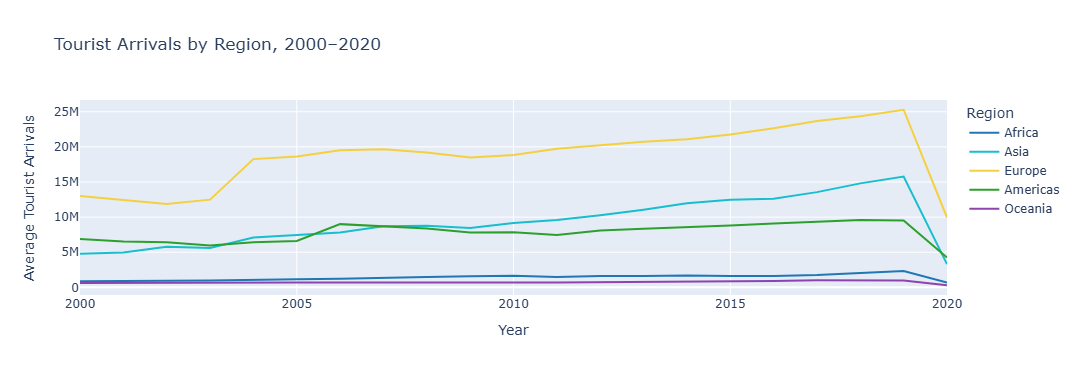

In [359]:
tourism = merged[merged['indicator'] == 'tourist_arrivals'].copy()
tourism = tourism[(tourism['year'] >= 2000) & (tourism['year'] <= 2020)]
trend_tourism = tourism.groupby(['year', 'region'], as_index=False).agg(
    avg_arrivals=("value", "mean")
)

fig = px.line(
    trend_tourism,
    x='year',
    y='avg_arrivals',
    color='region',
    category_orders={'region': list(region_colors.keys())},
    color_discrete_map=region_colors,
    labels={'avg_arrivals': 'Average Tourist Arrivals', 'year': 'Year', 'region': 'Region'},
    title='Tourist Arrivals by Region, 2000–2020'
)
fig.show()

In [360]:
dictionary[dictionary['indicator'].str.contains('life', case=False)]

,indicator,category,description,unit,n_countries,n_rows,year_min,year_max,sources
5,life_expectancy,Demographics,Life expectancy at birth,years,216,5382,2000,2024,world_bank


## GDP per Capita vs. Life Expectancy

Compares GDP per capita (log scale) against life expectancy for each country,
colored by region.

**Key pattern:** life expectancy rises sharply with GDP at lower income
levels, then flattens out at higher incomes — a classic diminishing-returns
relationship seen globally.

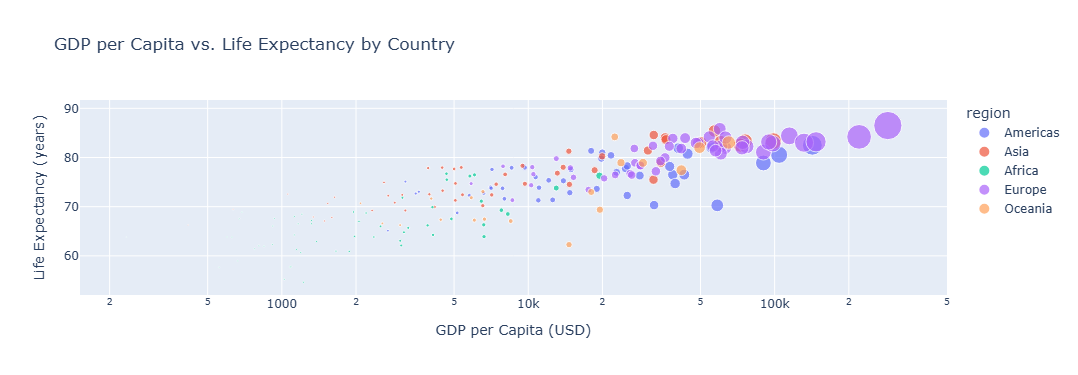

In [361]:
import plotly.express as px

gdp = merged[merged['indicator'] == 'gdp_per_capita_usd']
gdp_latest = gdp.sort_values('year').groupby('country_code3', as_index=False).agg(
    gdp_per_capita=("value", "last")
)

life = merged[merged['indicator'] == 'life_expectancy']
life_latest = life.sort_values('year').groupby('country_code3', as_index=False).agg(
    life_expectancy=("value", "last")
)

country_info = merged[['country_code3', 'country_name', 'region', 'income_level']].drop_duplicates('country_code3')

scatter_data = gdp_latest.merge(life_latest, on='country_code3').merge(country_info, on='country_code3')

fig = px.scatter(
    scatter_data,
    x='gdp_per_capita',
    y='life_expectancy',
    color='region',
    size='gdp_per_capita',
    hover_name='country_name',
    labels={'gdp_per_capita': 'GDP per Capita (USD)', 'life_expectancy': 'Life Expectancy (years)'},
    title='GDP per Capita vs. Life Expectancy by Country',
    log_x=True
)
fig.show()

## Conclusion

This project explored global economic and demographic indicators across
200+ countries (World Bank, IMF data, 2000–2025+). After cleaning and
merging three source tables, key patterns emerged:

- **Poverty is strongly tied to income classification** — average poverty
  rate drops from ~50% in low-income countries to under 1% in high-income
  countries.
- **GDP and life expectancy show diminishing returns** — life expectancy
  rises sharply with GDP at lower income levels, then flattens at higher
  incomes.
- **Regional GDP gaps are persistent**, not converging over 2000–2024.
- **Geographic patterns are clear** in the poverty choropleth, concentrated
  in specific regions.

### Limitations
Some indicators have limited year coverage (e.g. tourism data ends 2020),
and a few missing reference values were filled with placeholders rather
than dropped, to preserve full country coverage.